<a href="https://colab.research.google.com/github/karthick-2008/DSA0404-Fundamental-Of-Data-Science/blob/main/Q.NO_17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Saving 17customer_reviews_FINAL.xlsx to 17customer_reviews_FINAL (3).xlsx
Enter the number of top words: 10

Top 10 Most Frequent Words
--------------------------------
size : 98
top : 96
love : 82
fit : 76
wear : 73
dress : 69
like : 69
fabric : 69
would : 64
color : 62


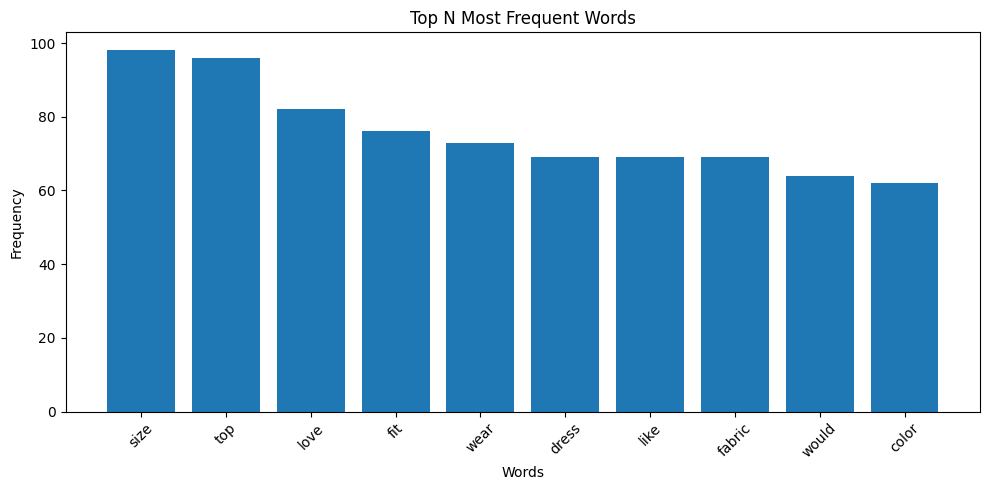

In [8]:

import pandas as pd
import re
import nltk
import matplotlib.pyplot as plt
from collections import Counter
from google.colab import files
from nltk.corpus import stopwords

# Download stopwords
nltk.download('stopwords')

# Upload dataset
uploaded = files.upload()
file_name = list(uploaded.keys())[0]

# Load dataset
if file_name.endswith('.xlsx'):
    df = pd.read_excel(file_name)
else:
    try:
        df = pd.read_csv(file_name, encoding='utf-8')
    except UnicodeDecodeError:
        df = pd.read_csv(file_name, encoding='latin-1')

# Extract customer reviews
text = " ".join(df["Review Text"].dropna().astype(str)).lower()

# Remove punctuation
text = re.sub(r'[^a-z\s]', '', text)

# Remove stopwords
stop_words = set(stopwords.words('english'))
words = [word for word in text.split() if word not in stop_words]

# Calculate word frequency
word_frequency = Counter(words)

# Get user input
N = int(input("Enter the number of top words: "))

# Display top N words
top_words = word_frequency.most_common(N)

print("\nTop", N, "Most Frequent Words")
print("--------------------------------")

for word, count in top_words:
    print(word, ":", count)

# Plot bar graph
if top_words:
    labels, values = zip(*top_words)

    plt.figure(figsize=(10, 5))
    plt.bar(labels, values)
    plt.xlabel("Words")
    plt.ylabel("Frequency")
    plt.title("Top N Most Frequent Words")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No words available.")
